# Velocity-only p(v | R) versus joint p(x, y, v): does modelling the positions change the posterior?

## The question

The production NLE conditions on the projected radius and models only
the velocity,

$$\mathcal L_{\rm los}(\theta) = \prod_i p(v_i \mid \log R_i,\, \theta,\,
\log r_{1/2},\, \sigma_i).$$

The alternative (`condition_on_position = False`) models the sky position
too:

$$\mathcal L_{\rm joint}(\theta) = \prod_i p(x_i, y_i, v_i \mid \theta,\,
\log r_{1/2},\, \sigma_i).$$

With $r_{1/2}$ fixed at its photometric value, the joint density
factorises exactly as $p(v \mid R, \theta, r_{1/2})\, p(x, y \mid
r_{1/2})$, and the second factor is the projected Plummer profile, which
carries **no** $\theta$. So $\log\mathcal L_{\rm joint} = \log\mathcal
L_{\rm los} + {\rm const}$ and the two posteriors are identical *if both
flows are exact*. A position-only selection function multiplies the
velocity-only likelihood by a $\theta$-independent factor as well, which
is the Jeans-style argument for conditioning on $R$ in the first place.

What can differ is the approximation. The joint flow has to *learn* that
its position marginal does not depend on $\theta$; nothing in the
training objective enforces it. Any residual dependence is a per-star
error that is coherent across a galaxy's stars, so $\epsilon$ nats per
star becomes $N\epsilon$ nats in the galaxy likelihood. This notebook:

1. builds both galaxy likelihoods on a Draco mock,
2. scans and samples them,
3. measures the "leak" $\log\mathcal L_{\rm joint} - \log\mathcal
   L_{\rm los}$ over the posterior, a constant for an exact position
   factor,
4. shows the batch result on all twelve mocks, with and without the
   Walker 2023 selection.

**Models.** Both on shards 0-1, T2 architecture, 30k steps: the
velocity-only model `errtest_noisy` (run `6xaw28uw`) and the joint model
`errtest_joint` (`configs/nle_8p_v4_errtest.py:joint`), which differs
only in `condition_on_position = condition_on_radius = False`.

In [1]:
# Paths and imports.
import math
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))                            # nle_dsph package
sys.path.insert(0, os.path.expanduser('~/my_modules'))   # dsph_analysis
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from nle import NLE                  # Lightning module: flow + normalisation
from transforms import StarBatch     # the per-star container the model reads
from diagnostics.pit_by_regime import best_checkpoint, load_shard

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

MODELS = Path(os.path.expanduser(
    '~/scratch/projects/sbi_dsph/trained_models/nle/nle_8p_ZhaoPlumCOM_v4'))
OUT = Path(os.path.expanduser('~/scratch/projects/nle_dsph'))
LABELS = ('dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0',
          'df_beta0', 'df_log_ra')

In [2]:
import dsph_analysis.kinematic_io as kio
from diagnostics.mock_sf_compare import (
    MOCKS, SETS, load_mock, truth_labels, PRIOR_MIN, PRIOR_MAX, log_rho_150)

los = NLE.load_from_checkpoint(
    best_checkpoint(MODELS / '6xaw28uw'), map_location=dev,
    pre_transforms=None).eval()

# The joint run: the newest run dir whose config snapshot is named
# errtest_joint.
joint_runs = sorted(
    d for d in MODELS.iterdir()
    if (d / 'config_snapshot.json').exists()
    and '"errtest_joint"' in (d / 'config_snapshot.json').read_text())
joint = NLE.load_from_checkpoint(
    best_checkpoint(joint_runs[-1]), map_location=dev,
    pre_transforms=None).eval()

print('velocity-only  target', los.target_fields,
      '  context', los.context_fields)
print('joint          target', joint.target_fields,
      '  context', joint.context_fields, '  (run', joint_runs[-1].name + ')')
print('both condition on log r_half (`cond`); neither infers it')

[NLE] Context MLP 10 -> 64 with 26,176 parameters
[NLE] Modeling p(vel | pos,theta,cond,vel_error)
[NLE] Flow built with 111,196 parameters
[NLE] Context MLP 9 -> 64 with 26,048 parameters
[NLE] Modeling p(pos,vel | theta,cond,vel_error)
[NLE] Flow built with 136,468 parameters
velocity-only  target ['vel']   context ['pos', 'theta', 'cond', 'vel_error']
joint          target ['pos', 'vel']   context ['theta', 'cond', 'vel_error']   (run 5srmof4g)
both condition on log r_half (`cond`); neither infers it


## 1. A mock through the pipeline's loader

The mocks live in `vr_catalogs/mock/icrs`: six profiles times two sets,
`draco1_walker23_icrs` (510 stars, the Walker 2023 footprint applied) and
`draco1_walker23_noSF` (200 stars, no selection). The `mock_icrs` loader
does what the NPE pipeline does: perspective correction, the $|v_{\rm
los}| < 50$ km/s cut, and the RA/Dec to kpc projection at Draco's LVDB
distance. The truth file stores $r_s$ and $r_a$ in kpc; the labels use
units of $r_{1/2}$, so `truth_labels` divides them out.

510 stars | r_half = 0.22924 kpc | median sigma_v = 1.02 km/s
truth (label space): {'dm_alpha': np.float64(1.0), 'dm_beta': np.float64(3.0), 'dm_gamma': np.float64(1.0), 'dm_log_rdm': np.float64(0.64), 'dm_log_rho0': np.float64(7.367), 'df_beta0': np.float64(0.0), 'df_log_ra': np.float64(3.0)}
true log10 rho(150 pc) = 8.070


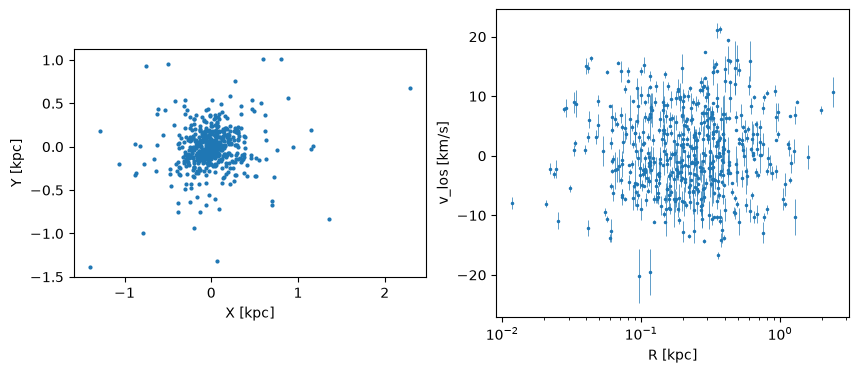

In [3]:
meta = kio.load_meta('draco_1')
rhalf = float(meta.rhalf_kpc.value)
lrs = float(np.log10(rhalf))

SET, PROF = 'walker23', 'CuspIso'      # change these for another mock
obs = load_mock(SETS[SET], PROF, meta)  # X, Y [kpc], v, err [km/s]
params = pd.read_csv(MOCKS / SETS[SET] / 'mock_catalog_params.csv')
truth = truth_labels(params[params.profile == PROF].iloc[0], rhalf)
tr150 = float(log_rho_150(truth[None], lrs)[0])

print(f'{len(obs["v"])} stars | r_half = {rhalf} kpc | '
      f'median sigma_v = {np.median(obs["err"]):.2f} km/s')
print('truth (label space):', dict(zip(LABELS, truth.round(3))))
print(f'true log10 rho(150 pc) = {tr150:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(obs['X'], obs['Y'], s=4)
ax[0].set_aspect('equal')
ax[0].set(xlabel='X [kpc]', ylabel='Y [kpc]')
ax[1].errorbar(np.hypot(obs['X'], obs['Y']), obs['v'], obs['err'],
               fmt='.', ms=3, lw=0.5)
ax[1].set(xscale='log', xlabel='R [kpc]', ylabel='v_los [km/s]')
plt.show()

## 2. The galaxy log-likelihood

Eight parameters: the seven labels and the systemic velocity $v_{\rm
sys}$. For each parameter vector, every star gets the same $\theta$
(`repeat_interleave`), the observed velocities are shifted by $v_{\rm
sys}$, and the per-star $\log p$ are summed. The same function serves
both models: the joint one reads `pos` as part of its target, the
velocity-only one as context. Several parameter vectors are evaluated in
one batch, which is what makes the GPU sampler below fast.

In [4]:
X, Y, v = (torch.tensor(obs[k], device=dev) for k in ('X', 'Y', 'v'))
err = torch.tensor(obs['err'], device=dev).view(-1, 1)
n = len(v)


def log_like(model, theta):
    """Galaxy log-likelihood for each row of theta.

    Args:
        model: A trained NLE.
        theta: Parameters, shape (k, 8): seven labels and v_sys.

    Returns:
        Array of shape (k,).
    """
    t = torch.tensor(np.atleast_2d(theta), dtype=torch.float32, device=dev)
    nw = len(t)
    batch = StarBatch(
        pos=torch.stack([X, Y], 1).repeat(nw, 1),
        vel=(v.repeat(nw) - t[:, 7].repeat_interleave(n)).view(-1, 1),
        vel_error=err.repeat(nw, 1),
        theta=t[:, :7].repeat_interleave(n, 0),
        cond=torch.full((nw * n, 1), lrs, device=dev))
    with torch.no_grad():
        lp = model.log_prob(batch).view(nw, n)
    lp = torch.where(torch.isfinite(lp), lp, torch.full_like(lp, -1e30))
    return lp.sum(1).cpu().numpy()


# v_sys = 0: the loader puts the mock in Draco's rest frame.
theta_true = np.append(truth, 0.0)
print(f'log L at the truth:  velocity-only {log_like(los, theta_true)[0]:.1f}'
      f'   joint {log_like(joint, theta_true)[0]:.1f}')
print('(the difference is sum_i log p(x_i, y_i | r_half) plus the '
      'vel_scale Jacobian: a constant in theta if the joint model '
      'is exact)')

log L at the truth:  velocity-only 985.5   joint 4457.1
(the difference is sum_i log p(x_i, y_i | r_half) plus the vel_scale Jacobian: a constant in theta if the joint model is exact)


## 3. A one-dimensional scan

Vary one label with the others held at the truth. Up to a vertical shift
the two curves should coincide; a difference in **shape** is $\theta$
leaking into the learned position factor.

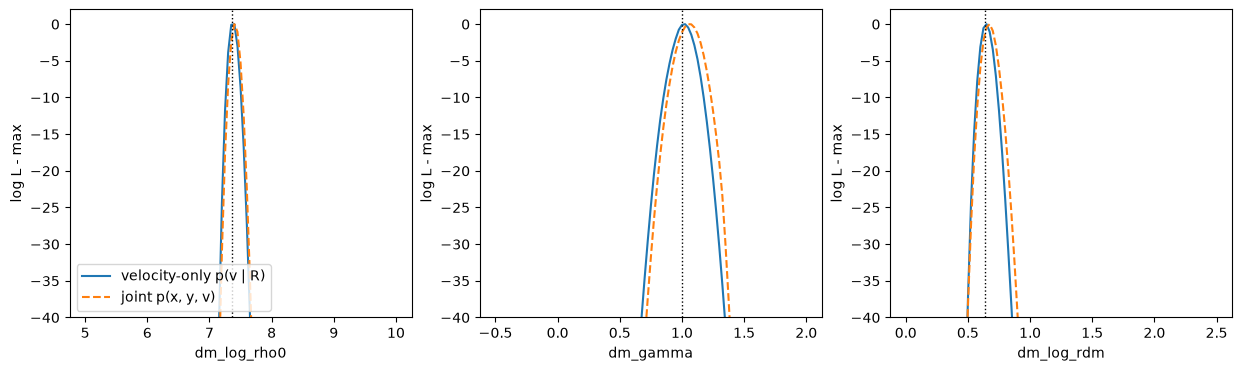

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ('dm_log_rho0', 'dm_gamma', 'dm_log_rdm')):
    k = LABELS.index(name)
    grid = np.linspace(PRIOR_MIN[k], PRIOR_MAX[k], 101)
    scan = np.tile(theta_true, (101, 1))
    scan[:, k] = grid
    for model, label, ls in ((los, 'velocity-only p(v | R)', '-'),
                             (joint, 'joint p(x, y, v)', '--')):
        ll = log_like(model, scan)
        ax.plot(grid, ll - ll.max(), ls, label=label)
    ax.axvline(truth[k], color='k', ls=':', lw=1)
    ax.set(ylim=(-40, 2), xlabel=name, ylabel='log L - max')
axes[0].legend()
plt.show()

## 4. Sampling the two posteriors

`emcee` over the eight parameters with the 8p_v4 box prior; all walkers
are evaluated in one GPU batch (`vectorize=True`), with the
differential-evolution moves of the T2 run. 48 walkers times 1000 steps
is enough to see the posterior here; the batch script uses 64 times
4000.

In [6]:
import emcee


def sample(model, n_walkers=48, n_steps=1000, seed=0):
    """Flat posterior chain over (7 labels, v_sys) for one model."""
    def log_post(th):
        out = np.full(len(th), -np.inf)
        ok = np.all((th >= PRIOR_MIN) & (th <= PRIOR_MAX), axis=1)
        if ok.any():
            out[ok] = log_like(model, th[ok])
        return out

    rng = np.random.default_rng(seed)
    p0 = rng.uniform(PRIOR_MIN, PRIOR_MAX, (n_walkers, 8))
    p0[:, 7] = np.median(obs['v']) + rng.normal(0, 1, n_walkers)
    moves = [(emcee.moves.DEMove(), 0.8),
             (emcee.moves.DESnookerMove(), 0.2)]
    sampler = emcee.EnsembleSampler(n_walkers, 8, log_post,
                                    vectorize=True, moves=moves)
    sampler.run_mcmc(p0, n_steps, progress=False)
    return sampler.get_chain(discard=n_steps // 2, flat=True)


chains = {'velocity-only': sample(los), 'joint': sample(joint)}
for name, chain in chains.items():
    lo, med, hi = np.percentile(log_rho_150(chain[:, :7], lrs),
                                [16, 50, 84])
    hw = (hi - lo) / 2
    print(f'{name:14s} log10 rho(150 pc) = {med:.3f} +- {hw:.3f}    '
          f'z = {(med - tr150) / hw:+.2f}    (truth {tr150:.3f})')

velocity-only  log10 rho(150 pc) = 8.097 +- 0.040    z = +0.69    (truth 8.070)
joint          log10 rho(150 pc) = 8.133 +- 0.064    z = +0.98    (truth 8.070)


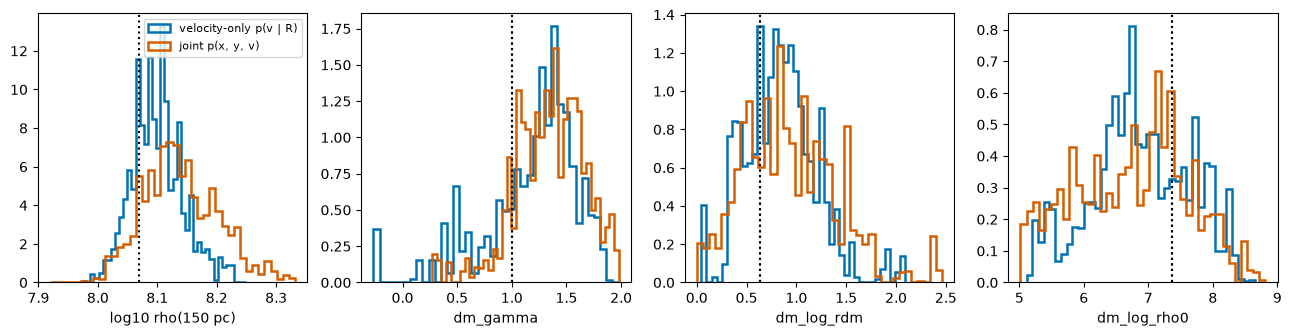

In [7]:
# Marginals of log rho(150 pc) and of the three labels that set it.
STYLE = {'velocity-only': ('velocity-only p(v | R)', '#0072B2'),
         'joint': ('joint p(x, y, v)', '#D55E00')}
keys = [LABELS.index(k) for k in ('dm_gamma', 'dm_log_rdm', 'dm_log_rho0')]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for name, chain in chains.items():
    label, color = STYLE[name]
    axes[0].hist(log_rho_150(chain[:, :7], lrs), bins=40, histtype='step',
                 lw=1.8, color=color, density=True, label=label)
    for ax, k in zip(axes[1:], keys):
        ax.hist(chain[:, k], bins=40, histtype='step', lw=1.8,
                color=color, density=True)
        ax.set_xlabel(LABELS[k])
        ax.axvline(truth[k], color='k', ls=':')
axes[0].axvline(tr150, color='k', ls=':')
axes[0].set_xlabel('log10 rho(150 pc)')
axes[0].legend(fontsize=8)
plt.show()

## 5. The leak diagnostic

$$\Delta(\theta) \equiv \log\mathcal L_{\rm joint}(\theta) -
\log\mathcal L_{\rm los}(\theta) = \sum_i \log p(x_i, y_i \mid \theta,
r_{1/2}).$$

For an exact position factor this is the same number at every $\theta$.
Evaluate it on samples of the velocity-only posterior: its standard
deviation is the size of the leak in nats at the galaxy level, and its
correlation with $\log\rho(150\,{\rm pc})$ says whether the leak pulls
the density posterior in a definite direction.

leak: std 2.06 nats over the posterior; corr with log rho(150 pc) +0.40   (exact model: 0, 0)
per star that is 0.0040 nats, below what a per-star PIT test can see


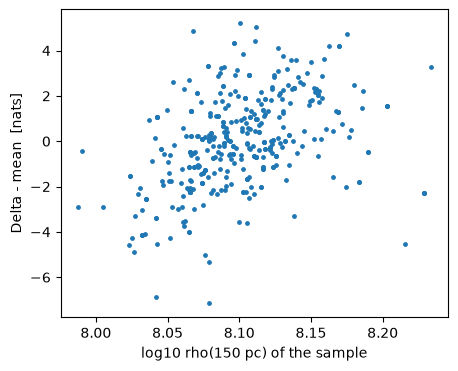

In [8]:
rng = np.random.default_rng(1)
idx = rng.choice(len(chains['velocity-only']), 400, replace=False)
th = chains['velocity-only'][idx]
delta = log_like(joint, th) - log_like(los, th)
lr = log_rho_150(th[:, :7], lrs)
corr = np.corrcoef(delta, lr)[0, 1]
print(f'leak: std {delta.std():.2f} nats over the posterior; '
      f'corr with log rho(150 pc) {corr:+.2f}   (exact model: 0, 0)')
print(f'per star that is {delta.std() / n:.4f} nats, below what a '
      'per-star PIT test can see')

plt.figure(figsize=(5, 4))
plt.scatter(lr, delta - delta.mean(), s=6)
plt.xlabel('log10 rho(150 pc) of the sample')
plt.ylabel('Delta - mean  [nats]')
plt.show()

## 6. All twelve mocks

`diagnostics/mock_sf_compare.py` runs both models on every mock with 64
times 4000 steps and records the leak diagnostic;
`diagnostics/plot_mock_sf.py` makes the figures. Summary columns:
`median` and `halfwidth` of $\log_{10}\rho(150\,{\rm pc})$ per model
(dex), `z` against the truth, `hw_ratio` = joint half-width over
velocity-only half-width, and the leak std and correlation. The profile
figures show the dark-matter density and slope against 3-D radius, and
$\sigma_{\rm los}$ and $\kappa_{\rm los}$ against projected radius
(curves: Jeans model at the median draw; points: bin-averaged posterior
predictive; black: error-deconvolved binned data; dashed black: truth).
The corner plots show the seven labels with radii in kpc.

What to look for: whether the joint model's $z$ or half-width differs
between the `walker23` and `noSF` sets in a way the velocity-only
model's does not; that would be the selection acting through the
learned position factor.

In [9]:
chains_dir = OUT / 'mock_sf'
df = pd.read_csv(chains_dir / 'mock_sf_compare.csv')
wide = df.pivot_table(index=['set', 'mock'], columns='model',
                      values=['median', 'halfwidth', 'z'])
wide['hw_ratio'] = wide[('halfwidth', 'joint')] / wide[('halfwidth', 'los')]
display(wide.round(3))
if 'leak_std_nats' in df:
    cols = ['set', 'mock', 'n_stars', 'leak_std_nats', 'leak_corr_rho150']
    display(df[df.model == 'joint'][cols].round(2))

halfwidth        median             z        hw_ratio
model                joint    los  joint    los  joint    los         
set      mock                                                         
noSF     CoreIso     0.092  0.070  8.092  7.948  1.722  0.200    1.307
         CoreOM      0.124  0.114  7.926  8.001 -0.067  0.583    1.083
         CoreTan     0.147  0.090  8.053  8.062  0.807  1.431    1.647
         CuspIso     0.108  0.075  8.086  8.049 -0.222 -0.810    1.451
         CuspOM      0.073  0.050  8.206  8.193  1.321  1.649    1.443
         CuspTan     0.112  0.076  8.117  8.231  0.060  1.590    1.478
walker23 CoreIso     0.195  0.053  8.085  7.931  0.977  0.700    3.694
         CoreOM      0.106  0.074  7.810  7.855 -0.791 -0.528    1.439
         CoreTan     0.105  0.078  7.881  7.892 -0.127 -0.023    1.351
         CuspIso     0.064  0.040  8.138  8.098  1.073  0.690    1.579
         CuspOM      0.091  0.050  8.318  8.146  2.736  1.519    1.817
         CuspTan     0.161  0.053  8.026  7.984 -0.275 -1.606    3.009

,set,mock,n_stars,leak_std_nats,leak_corr_rho150
1,walker23,CuspIso,510,2.12,0.39
3,walker23,CoreIso,510,2.00,0.04
5,walker23,CuspOM,510,3.64,0.52
7,walker23,CoreOM,510,1.96,-0.01
9,walker23,CuspTan,510,1.98,0.32
11,walker23,CoreTan,510,3.03,-0.29
13,noSF,CuspIso,200,1.12,0.24
15,noSF,CoreIso,200,1.50,0.48
17,noSF,CuspOM,200,1.14,0.10
19,noSF,CoreOM,200,1.46,-0.05


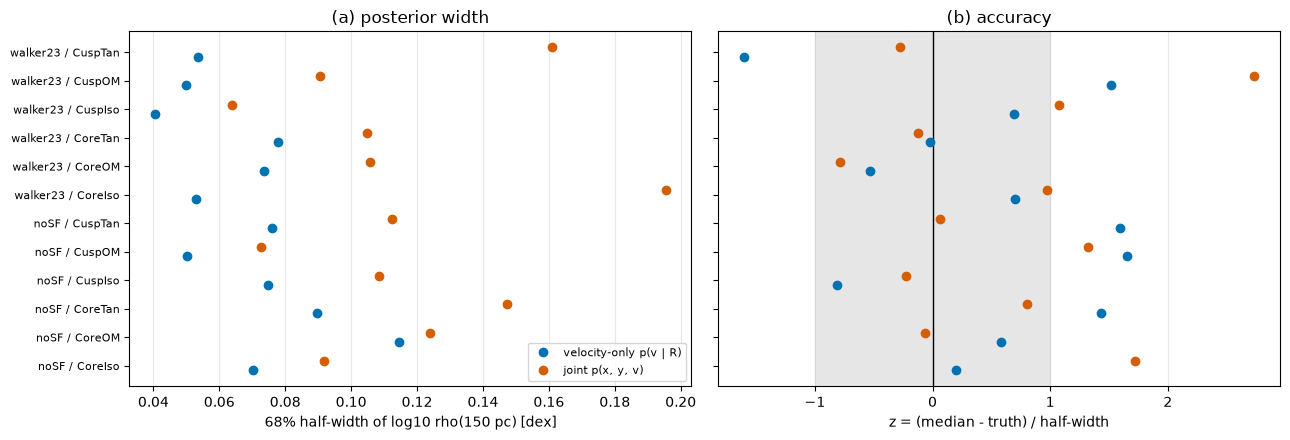

In [10]:
# All twelve mocks at a glance.
COL = {'los': '#0072B2', 'joint': '#D55E00'}
NAME = {'los': 'velocity-only p(v | R)', 'joint': 'joint p(x, y, v)'}
order = (df[df.model == 'los'].sort_values(['set', 'mock'])
         [['set', 'mock']].agg(' / '.join, axis=1).tolist())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
y = np.arange(len(order))
for model in ('los', 'joint'):
    d = df[df.model == model].sort_values(['set', 'mock'])
    off = -0.16 if model == 'los' else 0.16
    ax[0].errorbar(d.halfwidth, y + off, fmt='o', color=COL[model],
                   label=NAME[model])
    ax[1].errorbar(d.z, y + off, fmt='o', color=COL[model])
ax[0].set(xlabel='68% half-width of log10 rho(150 pc) [dex]',
          title='(a) posterior width')
ax[1].axvspan(-1, 1, color='0.9', zorder=0)
ax[1].axvline(0, color='k', lw=1)
ax[1].set(xlabel='z = (median - truth) / half-width', title='(b) accuracy')
ax[0].set_yticks(y, order, fontsize=8)
for a in ax:
    a.grid(alpha=0.3, axis='x')
ax[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

Now the two figures for one mock, built here rather than loaded
from disk. Change `SET` and `PROF` in section 1 and re-run from there to
look at a different one. The chains below are the batch ones, 64 walkers
by 4000 steps, not the short interactive chains from section 4.

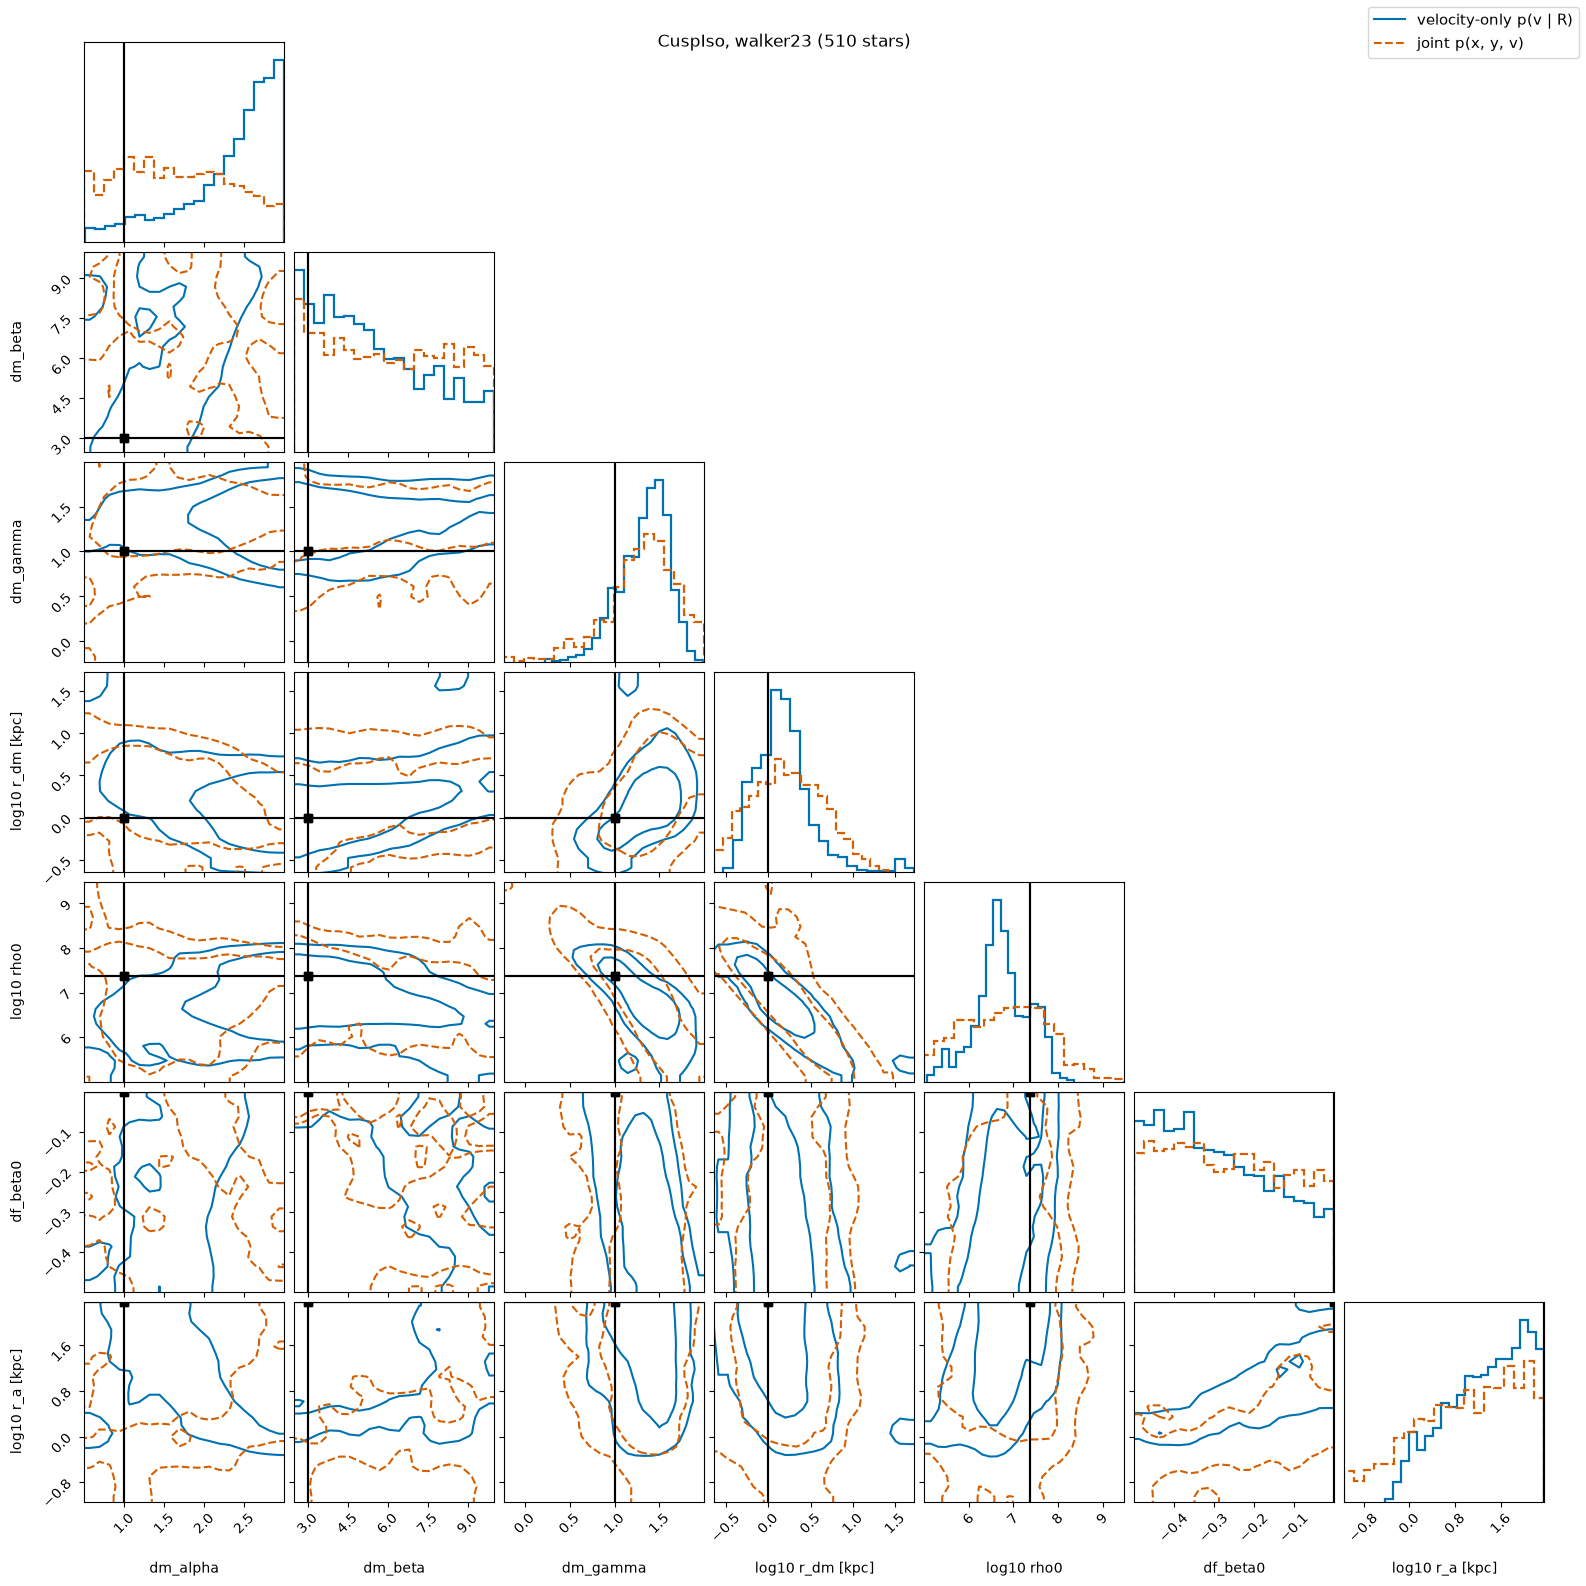

In [11]:
import corner
from diagnostics.profiles import LABELS_KPC

FILE_KEY = {'velocity-only p(v | R)': 'los', 'joint p(x, y, v)': 'joint'}
STYLE = {'velocity-only p(v | R)': dict(color='#0072B2', ls='-', marker='o'),
         'joint p(x, y, v)': dict(color='#D55E00', ls='--', marker='s')}
batch_chains = {nm: np.load(chains_dir / f'{SET}_{PROF}_{k}.npy')
                for nm, k in FILE_KEY.items()}


def to_kpc(chain):
    """Label-space chain (radii in r_half units) to radii in kpc."""
    out = chain[:, :7].copy()
    out[:, 3] += lrs      # log10 r_dm
    out[:, 6] += lrs      # log10 r_a
    return out


fig = None
for nm, chain in batch_chains.items():
    st = STYLE[nm]
    fig = corner.corner(
        to_kpc(chain), labels=LABELS_KPC, fig=fig, color=st['color'],
        hist_kwargs=dict(density=True, ls=st['ls'], lw=1.6),
        contour_kwargs=dict(linestyles=st['ls']), plot_datapoints=False,
        plot_density=False, levels=(0.68, 0.95), smooth=1.0,
        truths=to_kpc(truth[None])[0], truth_color='black')
handles = [plt.Line2D([], [], color=s['color'], ls=s['ls'], label=nm)
           for nm, s in STYLE.items()]
fig.legend(handles=handles, loc='upper right', fontsize=11)
fig.suptitle(f'{PROF}, {SET} ({len(obs["v"])} stars)', fontsize=12)
plt.show()

The profile figure needs three ingredients: the Zhao density
and slope evaluated on the posterior draws, the Jeans moments
$\sigma_{\rm los}^2$ and $\sigma_{\rm los}^4$ at the grid radii and at
each star (for the bin-averaged predictive), and the error-deconvolved
dispersion and kurtosis of the data in four radial bins. The Jeans
moments go through Agama and are the slow part, so they run in a worker
pool.

In [12]:
from multiprocessing import Pool

from dsph_analysis import vdisp, vkurtosis
from diagnostics.profiles import zhao_logrho, zhao_slope, moments, band, R_GRID

N_DRAWS = 80
R_stars = np.hypot(obs['X'], obs['Y']).astype(float)
vd, ed = obs['v'].astype(float), obs['err'].astype(float)

# Error-deconvolved dispersion and kurtosis of the data, four bins.
nb_ = len(R_stars) // 4
disp = vdisp.calc_vdisp_los_binned(R_stars, vd, ed, ntracer_per_bin=nb_,
                                   nbins_min=4, nbins_max=4, nsteps=1500,
                                   verbose=False)
kurt = vkurtosis.calc_kurtosis_los_binned(R_stars, vd, ed, ntracer_per_bin=nb_,
                                          nbins_min=4, nbins_max=4,
                                          verbose=False,
                                          sampler_args={'nsteps': 1500})
edges = list(zip(disp['R_mid'] - disp['R_em'], disp['R_mid'] + disp['R_ep']))

# Jeans moments for the posterior draws of each model.
ng = len(R_GRID)
R_all = np.concatenate([R_GRID, R_stars])
rng = np.random.default_rng(0)
pred = {}
with Pool(8) as pool:
    for nm, chain in batch_chains.items():
        draws = chain[rng.choice(len(chain), N_DRAWS, replace=False)]
        res = pool.map(moments, [(t[:7], lrs, R_all) for t in draws])
        s2 = np.array([r[0] for r in res])
        s4 = np.array([r[1] for r in res]) * s2 ** 2
        sig_bin, kap_bin = [], []
        for lo, hi in edges:
            m = (R_stars >= lo) & (R_stars <= hi)
            m2 = s2[:, ng:][:, m].mean(1)
            sig_bin.append(np.sqrt(m2))
            kap_bin.append(s4[:, ng:][:, m].mean(1) / m2 ** 2)
        pred[nm] = dict(draws=draws, s2=s2[:, :ng], s4=s4[:, :ng],
                        sig_bin=np.array(sig_bin).T,
                        kap_bin=np.array(kap_bin).T)
    s2t, kt = moments((truth, lrs, R_GRID))
print('ready:', {k: v['draws'].shape for k, v in pred.items()})

ready: {'velocity-only p(v | R)': (80, 8), 'joint p(x, y, v)': (80, 8)}


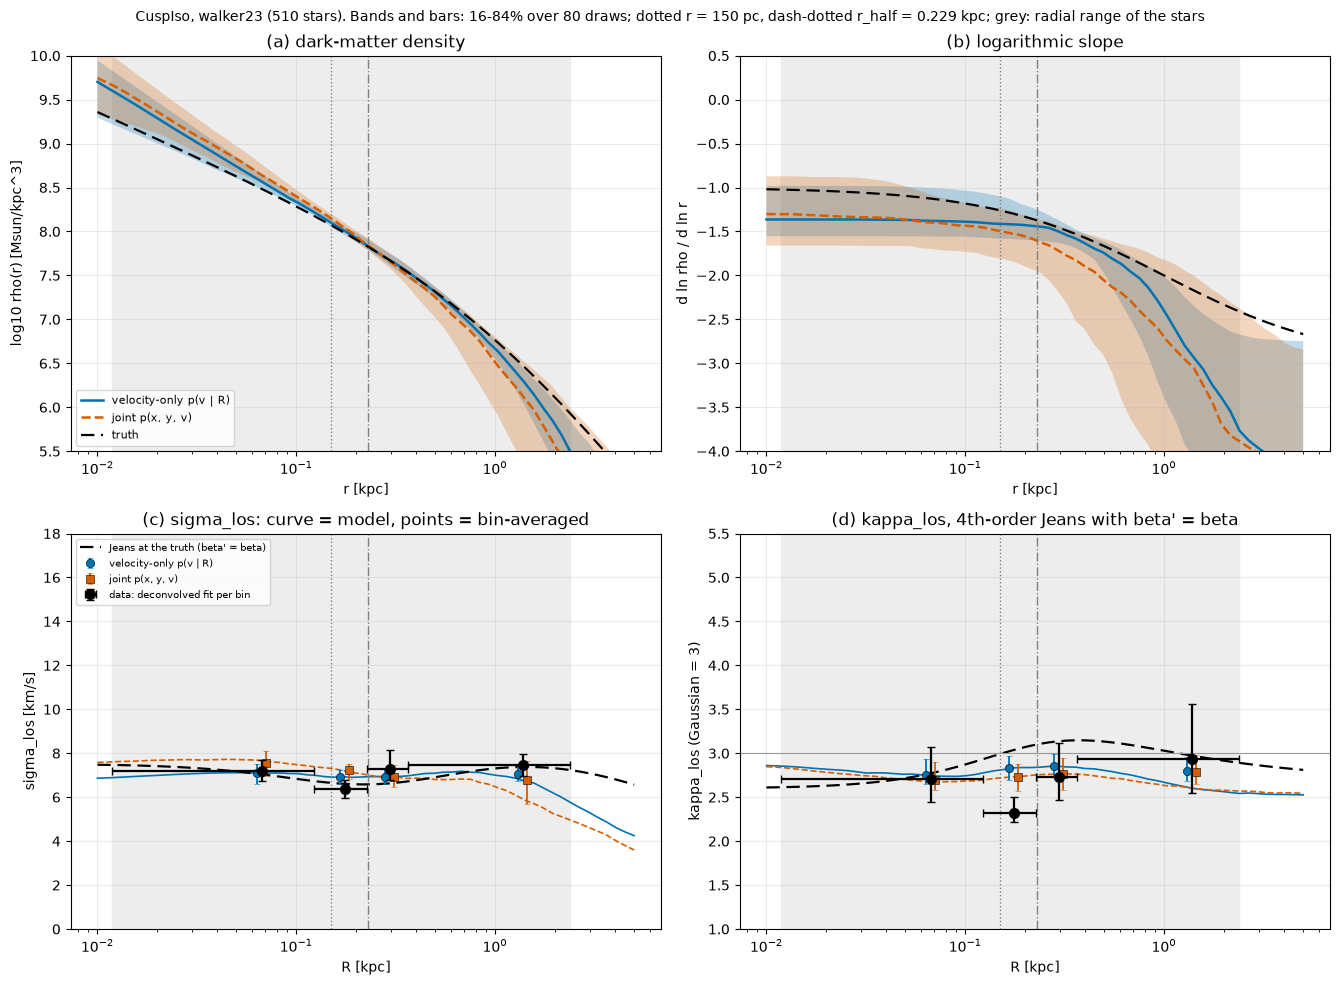

In [13]:
TRUTH = dict(color='black', ls=(0, (6, 3)), lw=1.6)
X_OFFSET = {'velocity-only p(v | R)': 0.95, 'joint p(x, y, v)': 1.05}

fig, axes = plt.subplots(2, 2, figsize=(13.5, 10))
ax = axes.ravel()
for nm, p in pred.items():
    st = STYLE[nm]
    kpc = to_kpc(p['draws'])
    band(ax[0], R_GRID, zhao_logrho(kpc, R_GRID), st, nm)
    band(ax[1], R_GRID, zhao_slope(kpc, R_GRID), st, nm)
    curves = ((ax[2], np.sqrt(p['s2']), p['sig_bin']),
              (ax[3], p['s4'] / p['s2'] ** 2, p['kap_bin']))
    for a, curve, binned in curves:
        a.plot(R_GRID, np.nanmedian(curve, 0), color=st['color'],
               ls=st['ls'], lw=1.2)
        q = np.nanpercentile(binned, [16, 50, 84], axis=0)
        a.errorbar(disp['R_mid'] * X_OFFSET[nm], q[1],
                   yerr=[q[1] - q[0], q[2] - q[1]], fmt=st['marker'],
                   color=st['color'], ms=6, capsize=2, lw=1.3, label=nm,
                   markeredgecolor='k', markeredgewidth=0.4, zorder=4)

tk = to_kpc(truth[None])
ax[0].plot(R_GRID, zhao_logrho(tk, R_GRID)[0], label='truth', **TRUTH)
ax[1].plot(R_GRID, zhao_slope(tk, R_GRID)[0], **TRUTH)
ax[2].plot(R_GRID, np.sqrt(s2t), label="Jeans at the truth (beta' = beta)",
           **TRUTH)
ax[3].plot(R_GRID, kt, **TRUTH)
ax[2].errorbar(disp['R_mid'], disp['sigma'],
               xerr=[disp['R_em'], disp['R_ep']],
               yerr=[disp['sigma_em'], disp['sigma_ep']], fmt='o', ms=7,
               capsize=3, lw=1.6, zorder=5, color='black',
               label='data: deconvolved fit per bin')
ax[3].errorbar(kurt['R_mid'], kurt['kappa'],
               xerr=[kurt['R_em'], kurt['R_ep']],
               yerr=[kurt['kappa_em'], kurt['kappa_ep']], fmt='o', ms=7,
               capsize=3, lw=1.6, zorder=5, color='black')
ax[3].axhline(3, color='0.6', lw=0.8)
for a in ax:
    a.set_xscale('log')
    a.axvline(0.15, color='0.5', ls=':', lw=1)
    a.axvline(rhalf, color='0.5', ls='-.', lw=1)
    a.axvspan(R_stars.min(), R_stars.max(), color='0.93', zorder=0)
    a.grid(alpha=0.25)
ax[0].set(xlabel='r [kpc]', ylabel='log10 rho(r) [Msun/kpc^3]',
          ylim=(5.5, 10), title='(a) dark-matter density')
ax[1].set(xlabel='r [kpc]', ylabel='d ln rho / d ln r', ylim=(-4, 0.5),
          title='(b) logarithmic slope')
ax[2].set(xlabel='R [kpc]', ylabel='sigma_los [km/s]', ylim=(0, 18),
          title='(c) sigma_los: curve = model, points = bin-averaged')
ax[3].set(xlabel='R [kpc]', ylabel='kappa_los (Gaussian = 3)',
          ylim=(1.0, 5.5),
          title="(d) kappa_los, 4th-order Jeans with beta' = beta")
ax[0].legend(fontsize=8, loc='lower left')
ax[2].legend(fontsize=7.5, loc='upper left')
fig.suptitle(f'{PROF}, {SET} ({len(obs["v"])} stars). Bands and bars: '
             f'16-84% over {N_DRAWS} draws; dotted r = 150 pc, dash-dotted '
             f'r_half = {rhalf:.3f} kpc; grey: radial range of the stars',
             fontsize=10)
fig.tight_layout()
plt.show()